# Association Rule Mining

## 1. Introduction

This notebook aims to discover frequent patterns and meaningful associations between clinical features in the CBIS-DDSM dataset using Association Rule Mining.

The analysis focuses on categorical clinical descriptors to identify relationships between mammographic characteristics.

In [52]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

mass_df = pd.read_csv("../data/mass_case_description_train_set.csv")
calc_df = pd.read_csv("../data/calc_case_description_train_set.csv")

calc_df = calc_df.rename(
    columns={"breast density": "breast_density"}
)

print("Mass:", mass_df.shape)
print("Calcification:", calc_df.shape)

Mass: (1318, 14)
Calcification: (1546, 14)


## 2. Preparing Transactions

Select the categorical clinical features from the Mass Dataset.

The target variable `pathology` and technical identifiers are excluded to discover associations independently of the diagnosis.

In [53]:
mass_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
    "assessment",
    "subtlety"
]

mass_transactions = mass_df[mass_features].copy()

for col in mass_transactions.columns:
    mass_transactions[col] = col + "=" + mass_transactions[col].astype(str)

mass_transactions = pd.get_dummies(mass_transactions, dtype=bool)

print("Transactions shape:", mass_transactions.shape)
display(mass_transactions.head())

Transactions shape: (1318, 53)


,breast_density_breast_density=1,breast_density_breast_density=2,breast_density_breast_density=3,breast_density_breast_density=4,left or right breast_left or right breast=LEFT,left or right breast_left or right breast=RIGHT,image view_image view=CC,image view_image view=MLO,mass shape_mass shape=ARCHITECTURAL_DISTORTION,mass shape_mass shape=ASYMMETRIC_BREAST_TISSUE,...,assessment_assessment=2,assessment_assessment=3,assessment_assessment=4,assessment_assessment=5,subtlety_subtlety=0,subtlety_subtlety=1,subtlety_subtlety=2,subtlety_subtlety=3,subtlety_subtlety=4,subtlety_subtlety=5
0,False,False,True,False,True,False,True,False,False,False,...,False,False,True,False,False,False,False,False,True,False
1,False,False,True,False,True,False,False,True,False,False,...,False,False,True,False,False,False,False,False,True,False
2,False,False,True,False,True,False,True,False,True,False,...,False,False,True,False,False,False,False,True,False,False
3,False,False,True,False,True,False,False,True,True,False,...,False,False,True,False,False,False,False,True,False,False
4,False,False,True,False,False,True,False,True,False,False,...,False,False,True,False,False,False,False,False,False,True


## 3. Frequent Itemset Mining

Apply the Apriori algorithm to identify frequent combinations of clinical features.

The minimum support threshold is set to 0.05, meaning that an itemset must appear in at least 5% of transactions.

In [54]:
frequent_itemsets = apriori(
    mass_transactions,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

print("Frequent itemsets:", frequent_itemsets.shape[0])
print (frequent_itemsets.head(10))

Frequent itemsets: 354
     support                                           itemsets
7   0.539454             frozenset({image view_image view=MLO})
5   0.521244  frozenset({left or right breast_left or right ...
4   0.478756  frozenset({left or right breast_left or right ...
6   0.460546              frozenset({image view_image view=CC})
1   0.443854       frozenset({breast_density_breast_density=2})
26  0.411988                   frozenset({subtlety_subtlety=5})
21  0.404401               frozenset({assessment_assessment=4})
85  0.285281  frozenset({left or right breast_left or right ...
25  0.284522                   frozenset({subtlety_subtlety=4})
9   0.266313       frozenset({mass shape_mass shape=IRREGULAR})


## 4. Association Rules Generation

Generate association rules from the frequent itemsets using the confidence metric.

The minimum confidence threshold is set to 0.6.

In [55]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

rules = rules.sort_values(
    by="lift",
    ascending=False
)

print("Number of rules:", len(rules))

print (
    rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10)
)

Number of rules: 76
                                          antecedents  \
33               frozenset({assessment_assessment=0})   
45  frozenset({subtlety_subtlety=5, mass margins_m...   
50  frozenset({subtlety_subtlety=5, mass margins_m...   
66  frozenset({assessment_assessment=5, left or ri...   
61  frozenset({assessment_assessment=5, image view...   
63  frozenset({subtlety_subtlety=5, mass margins_m...   
6   frozenset({subtlety_subtlety=5, mass margins_m...   
10  frozenset({assessment_assessment=5, mass shape...   
73  frozenset({subtlety_subtlety=5, mass margins_m...   
44  frozenset({subtlety_subtlety=5, assessment_ass...   

                                          consequents   support  confidence  \
33    frozenset({mass margins_mass margins=OBSCURED})  0.068285    0.697674   
45               frozenset({assessment_assessment=5})  0.062215    0.872340   
50               frozenset({assessment_assessment=5})  0.059939    0.858696   
66  frozenset({mass margins_mass mar

## 5. Filtering and Interpreting Association Rules

Filter the generated rules to retain meaningful associations based on support, confidence, and lift.

The selected rules will be analyzed to identify relevant relationships between clinical features.

In [56]:
filtered_rules = rules[
    (rules["support"] >= 0.05) &
    (rules["confidence"] >= 0.70) &
    (rules["lift"] > 1.5)
].copy()

print("Filtered rules:", len(filtered_rules))

print (
    filtered_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Filtered rules: 30
                                          antecedents  \
45  frozenset({subtlety_subtlety=5, mass margins_m...   
50  frozenset({subtlety_subtlety=5, mass margins_m...   
66  frozenset({assessment_assessment=5, left or ri...   
61  frozenset({assessment_assessment=5, image view...   
63  frozenset({subtlety_subtlety=5, mass margins_m...   
6   frozenset({subtlety_subtlety=5, mass margins_m...   
10  frozenset({assessment_assessment=5, mass shape...   
73  frozenset({subtlety_subtlety=5, mass margins_m...   
44  frozenset({subtlety_subtlety=5, assessment_ass...   
58  frozenset({subtlety_subtlety=5, mass margins_m...   

                                          consequents   support  confidence  \
45               frozenset({assessment_assessment=5})  0.062215    0.872340   
50               frozenset({assessment_assessment=5})  0.059939    0.858696   
66  frozenset({mass margins_mass margins=SPICULATED})  0.052352    0.793103   
61  frozenset({mass margins_mass marg

## 6. Association Rules Visualization

Visualize the filtered association rules using support, confidence, and lift.

This visualization helps identify the strongest and most relevant associations between clinical features.

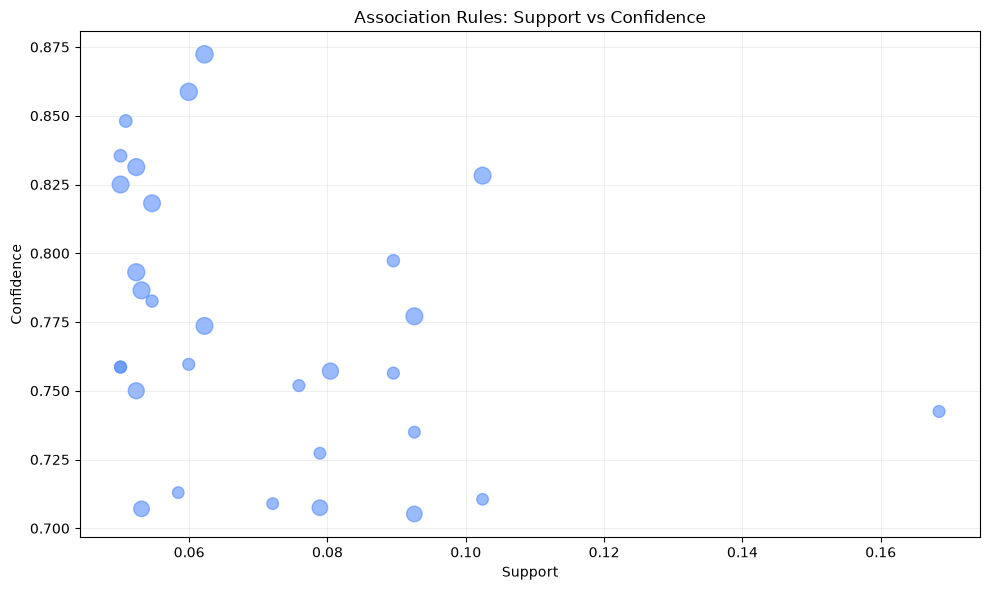

In [57]:
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    filtered_rules["support"],
    filtered_rules["confidence"],
    s=filtered_rules["lift"] * 40,
    alpha=0.6
)

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules: Support vs Confidence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Calcification Association Rules

Apply Association Rule Mining to the Calcification Dataset to discover frequent patterns and relationships between clinical features.

The target variable `pathology` is excluded from this analysis.

In [58]:
calc_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
    "assessment",
    "subtlety"
]

calc_transactions = calc_df[calc_features].copy()

for col in calc_transactions.columns:
    calc_transactions[col] = col + "=" + calc_transactions[col].astype(str)

calc_transactions = pd.get_dummies(
    calc_transactions,
    dtype=bool
)

print("Transactions shape:", calc_transactions.shape)

Transactions shape: (1546, 72)


### 7.1 Frequent Itemset Mining

Apply the Apriori algorithm to identify frequent combinations of clinical features in the Calcification Dataset.

The minimum support threshold is set to 0.05.

In [59]:
calc_itemsets = apriori(
    calc_transactions,
    min_support=0.05,
    use_colnames=True
)

calc_itemsets = calc_itemsets.sort_values(
    by="support",
    ascending=False
)

print("Frequent itemsets:", len(calc_itemsets))
print (calc_itemsets.head(10))

Frequent itemsets: 342
      support                                           itemsets
4    0.529107  frozenset({left or right breast_left or right ...
7    0.521992             frozenset({image view_image view=MLO})
19   0.487063               frozenset({assessment_assessment=4})
13   0.478655  frozenset({calc distribution_calc distribution...
6    0.478008              frozenset({image view_image view=CC})
5    0.470893  frozenset({left or right breast_left or right ...
10   0.429495       frozenset({calc type_calc type=PLEOMORPHIC})
115  0.351229  frozenset({assessment_assessment=4, calc distr...
2    0.348642       frozenset({breast_density_breast_density=3})
108  0.334411  frozenset({assessment_assessment=4, calc type_...


### 7.2 Association Rules Generation

Generate association rules from the frequent itemsets using a minimum confidence threshold of 0.6.

Rules will be ranked according to their lift values.

In [60]:
calc_rules = association_rules(
    calc_itemsets,
    metric="confidence",
    min_threshold=0.6
)

calc_rules = calc_rules.sort_values(
    by="lift",
    ascending=False
)

print("Number of rules:", len(calc_rules))

print (
    calc_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Number of rules: 235
                                           antecedents  \
217          frozenset({calc type_calc type=VASCULAR})   
172     frozenset({calc type_calc type=LUCENT_CENTER})   
157               frozenset({assessment_assessment=5})   
98   frozenset({breast_density_breast_density=4, ca...   
147  frozenset({calc type_calc type=PLEOMORPHIC, su...   
234  frozenset({calc type_calc type=PLEOMORPHIC, le...   
86   frozenset({calc type_calc type=PLEOMORPHIC, su...   
104  frozenset({subtlety_subtlety=3, calc type_calc...   
140  frozenset({calc type_calc type=PLEOMORPHIC, le...   
146  frozenset({calc type_calc type=PLEOMORPHIC, su...   

                                           consequents   support  confidence  \
217               frozenset({assessment_assessment=2})  0.053040    1.000000   
172               frozenset({assessment_assessment=2})  0.060155    1.000000   
157                   frozenset({subtlety_subtlety=5})  0.062743    0.610063   
98   frozenset({asse

### 7.3 Filtering Association Rules

Filter the generated rules using the following thresholds:

- Support >= 0.05
- Confidence >= 0.70
- Lift > 1.5

These thresholds help retain the strongest associations for further analysis.

In [61]:
calc_filtered_rules = calc_rules[
    (calc_rules["support"] >= 0.05) &
    (calc_rules["confidence"] >= 0.70) &
    (calc_rules["lift"] > 1.5)
].copy()

print("Filtered rules:", len(calc_filtered_rules))

print (
    calc_filtered_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].head(10)
)

Filtered rules: 129
                                           antecedents  \
217          frozenset({calc type_calc type=VASCULAR})   
172     frozenset({calc type_calc type=LUCENT_CENTER})   
234  frozenset({calc type_calc type=PLEOMORPHIC, le...   
86   frozenset({calc type_calc type=PLEOMORPHIC, su...   
104  frozenset({subtlety_subtlety=3, calc type_calc...   
140  frozenset({calc type_calc type=PLEOMORPHIC, le...   
146  frozenset({calc type_calc type=PLEOMORPHIC, su...   
101  frozenset({calc type_calc type=PLEOMORPHIC, br...   
155  frozenset({left or right breast_left or right ...   
190  frozenset({subtlety_subtlety=3, calc type_calc...   

                              consequents   support  confidence      lift  
217  frozenset({assessment_assessment=2})  0.053040    1.000000  3.207469  
172  frozenset({assessment_assessment=2})  0.060155    1.000000  3.207469  
234  frozenset({assessment_assessment=4})  0.050453    0.951220  1.952969  
86   frozenset({assessment_assessment

### 7.4 Association Rules Visualization

Visualize the filtered association rules using support, confidence, and lift.

The visualization highlights the strongest relationships between calcification features.

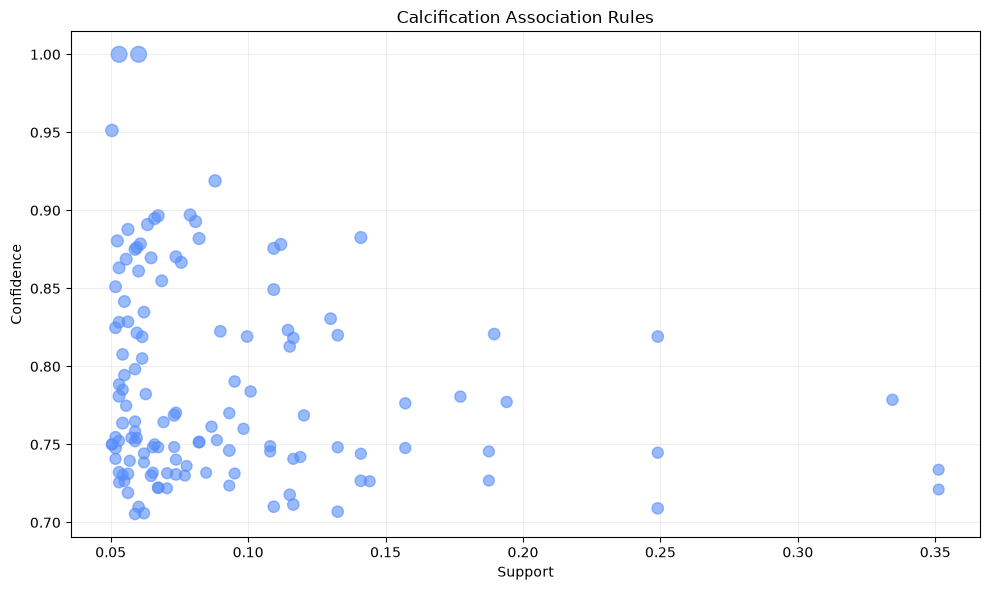

In [62]:
plt.figure(figsize=(10, 6))

plt.scatter(
    calc_filtered_rules["support"],
    calc_filtered_rules["confidence"],
    s=calc_filtered_rules["lift"] * 40,
    alpha=0.6
)

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Calcification Association Rules")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.5 Association Rules Summary

Association Rule Mining was applied to both Mass and Calcification datasets.

**Mass Dataset:**
- 53 items.
- 354 frequent itemsets.
- 76 generated association rules.
- 30 filtered rules.

**Calcification Dataset:**
- 72 items.
- 342 frequent itemsets.
- 235 generated association rules.
- 129 filtered rules.

The discovered rules reveal relationships between clinical features, providing additional insights into mammographic patterns.

These associations will contribute to the knowledge discovery process and subsequent semantic graph construction.

In [63]:
import os

os.makedirs("../data/processed", exist_ok=True)

# Save Mass association rules
filtered_rules.to_csv(
    "../data/processed/mass_association_rules.csv",
    index=False
)

# Save Calcification association rules
calc_filtered_rules.to_csv(
    "../data/processed/calc_association_rules.csv",
    index=False
)

print("Association rules saved successfully.")
print("Mass rules:", len(filtered_rules))
print("Calcification rules:", len(calc_filtered_rules))

Association rules saved successfully.
Mass rules: 30
Calcification rules: 129
